In [41]:
!pip install -q ultralytics

In [42]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("SmartPark model loaded successfully!")

SmartPark model loaded successfully!



image 1/1 /content/parkinglot.webp: 448x640 11 cell phones, 212.3ms
Speed: 16.5ms preprocess, 212.3ms inference, 2.7ms postprocess per image at shape (1, 3, 448, 640)


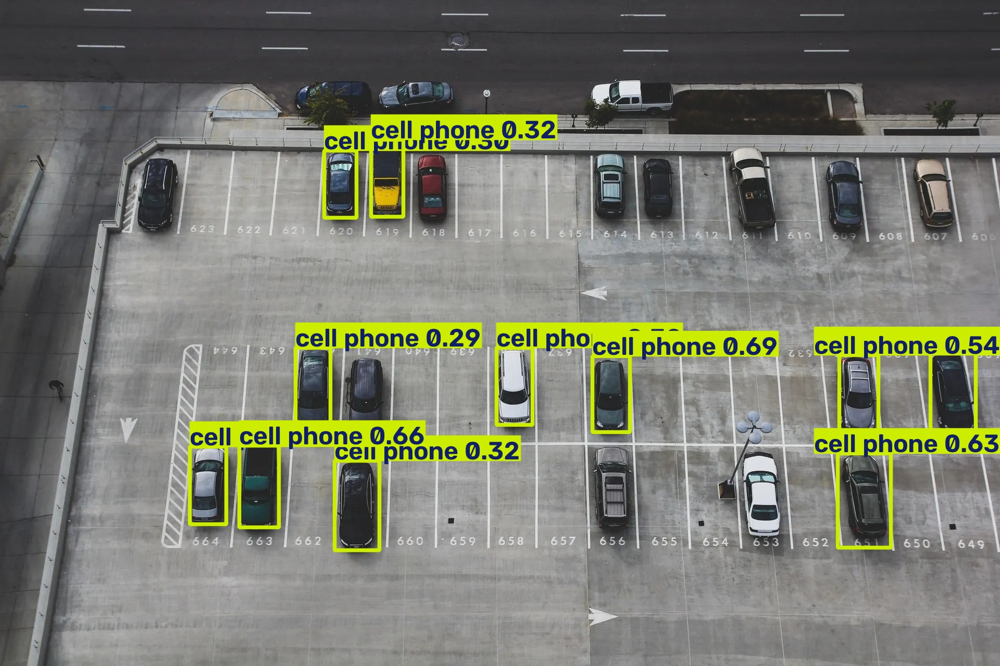

In [43]:

from IPython.display import display, Image

results = model.predict("/content/parkinglot.webp", conf=0.25)

results[0].save(filename="smartpark_detection.jpg")

display(Image(filename="smartpark_detection.jpg"))



image 1/1 /content/parkinglot.webp: 448x640 (no detections), 159.1ms
Speed: 4.8ms preprocess, 159.1ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)


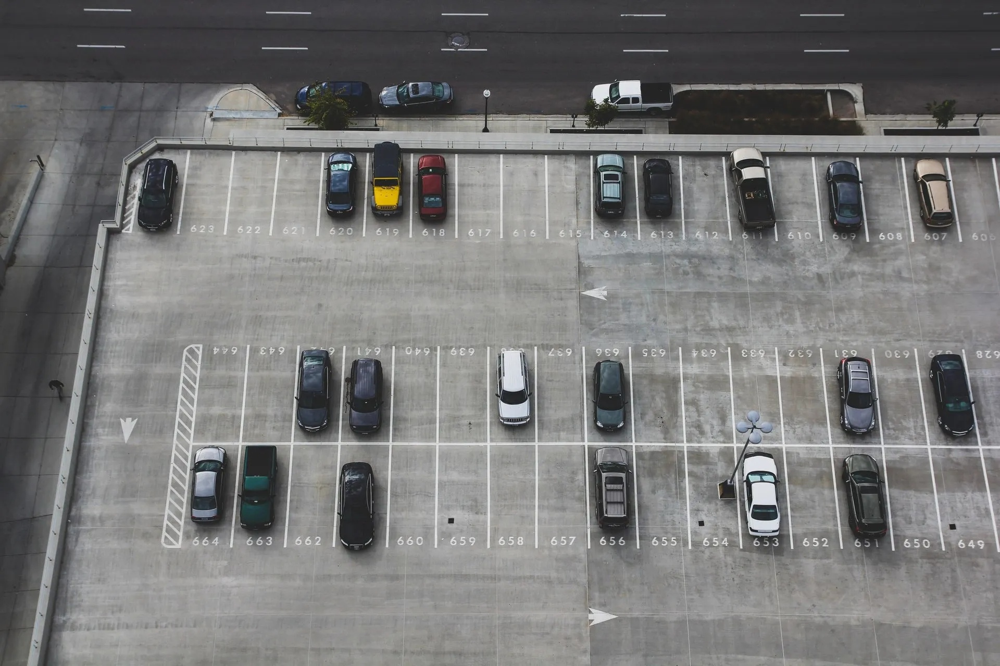

Vehicles detected: 0


In [44]:

from IPython.display import display, Image

results = model.predict(
    "/content/parkinglot.webp",
    conf=0.15,
    classes=[2, 3, 5, 7]
)

results[0].save(filename="smartpark_vehicles.jpg")

display(Image(filename="smartpark_vehicles.jpg"))

print("Vehicles detected:", len(results[0].boxes))



image 1/1 /content/parkinglot.webp: 864x1280 (no detections), 2322.6ms
Speed: 64.2ms preprocess, 2322.6ms inference, 6.6ms postprocess per image at shape (1, 3, 864, 1280)


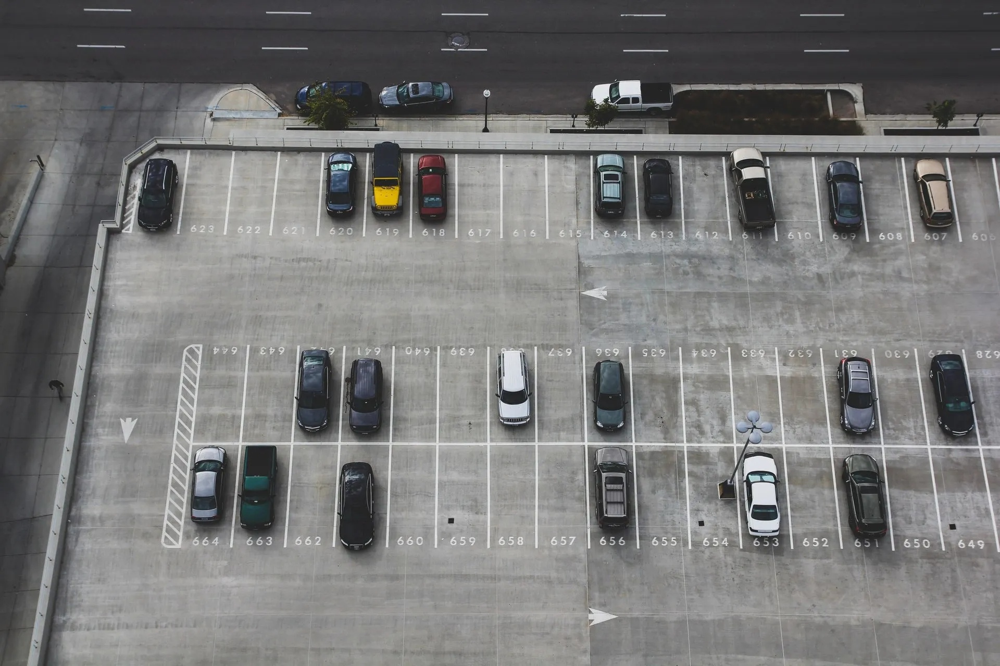

Vehicles detected: 0


In [45]:

from ultralytics import YOLO
from IPython.display import display, Image

model2 = YOLO("yolo11s.pt")

results2 = model2.predict(
    "/content/parkinglot.webp",
    conf=0.10,
    imgsz=1280,
    classes=[2, 3, 5, 7]
)

results2[0].save(filename="smartpark_test2.jpg")
display(Image(filename="smartpark_test2.jpg"))

print("Vehicles detected:", len(results2[0].boxes))


Image dimensions: (1280, 1920, 3)


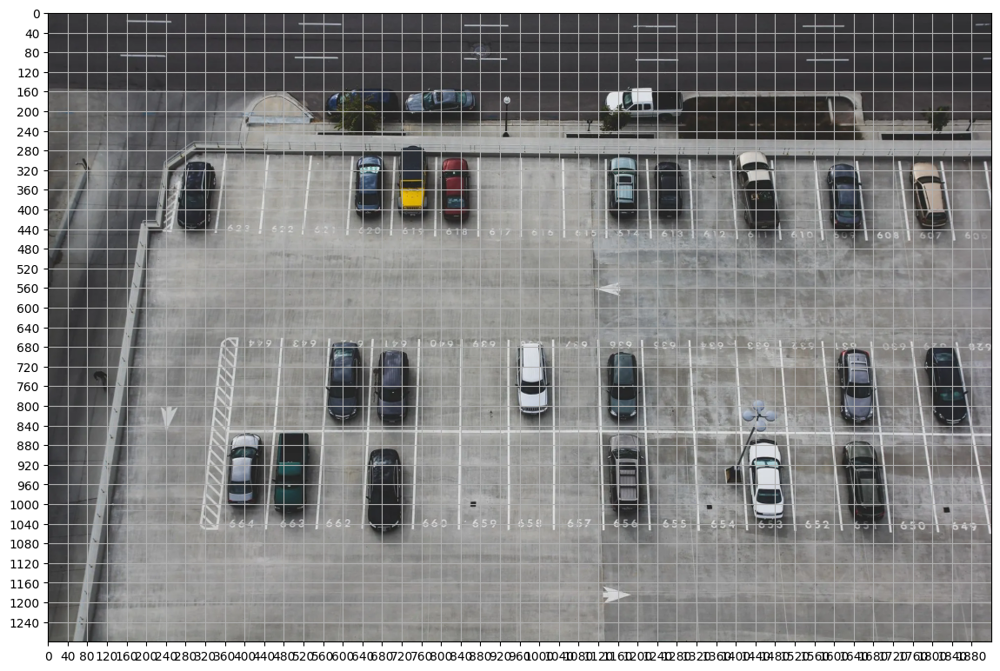

In [46]:
%matplotlib inline
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("/content/parkinglot.webp")
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image dimensions:", image.shape)

plt.figure(figsize=(14, 10))
plt.imshow(image_rgb)
plt.xlim(0, image.shape[1])
plt.ylim(image.shape[0], 0)
plt.xticks(range(0, image.shape[1], 40))
plt.yticks(range(0, image.shape[0], 40))
plt.grid()
plt.show()


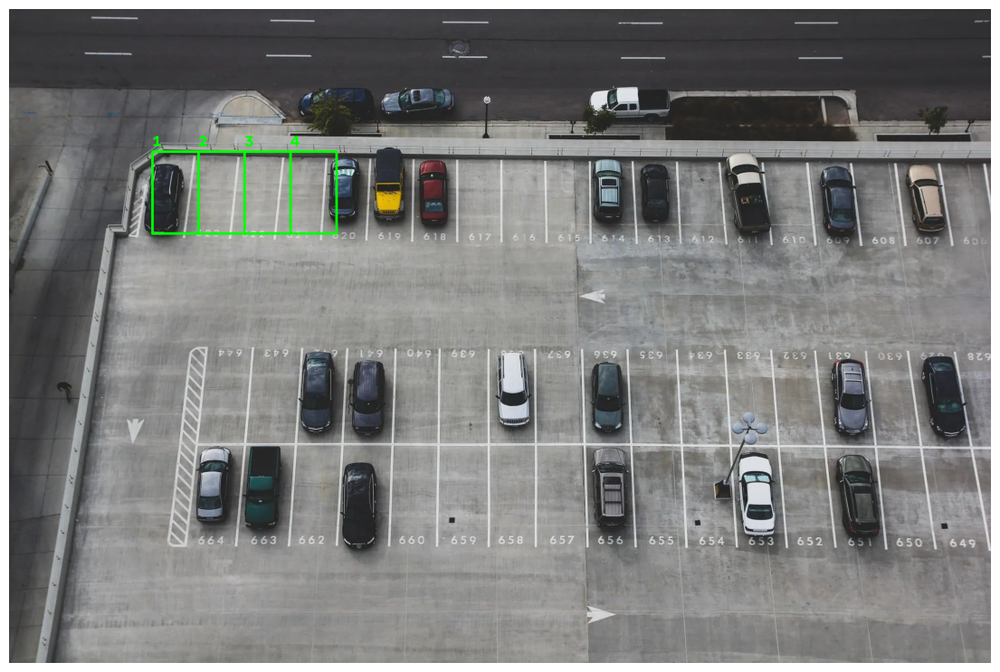

In [47]:

parking_spaces = [
    (280, 280, 370, 440),
    (370, 280, 460, 440),
    (460, 280, 550, 440),
    (550, 280, 640, 440)
]

preview = image_rgb.copy()

for i, (x1, y1, x2, y2) in enumerate(parking_spaces):
    cv2.rectangle(preview, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(preview, str(i + 1), (x1, y1 - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

plt.figure(figsize=(14, 10))
plt.imshow(preview)
plt.axis("off")
plt.show()


Space 1: Edge density = 0.099
Space 2: Edge density = 0.034
Space 3: Edge density = 0.039
Space 4: Edge density = 0.073


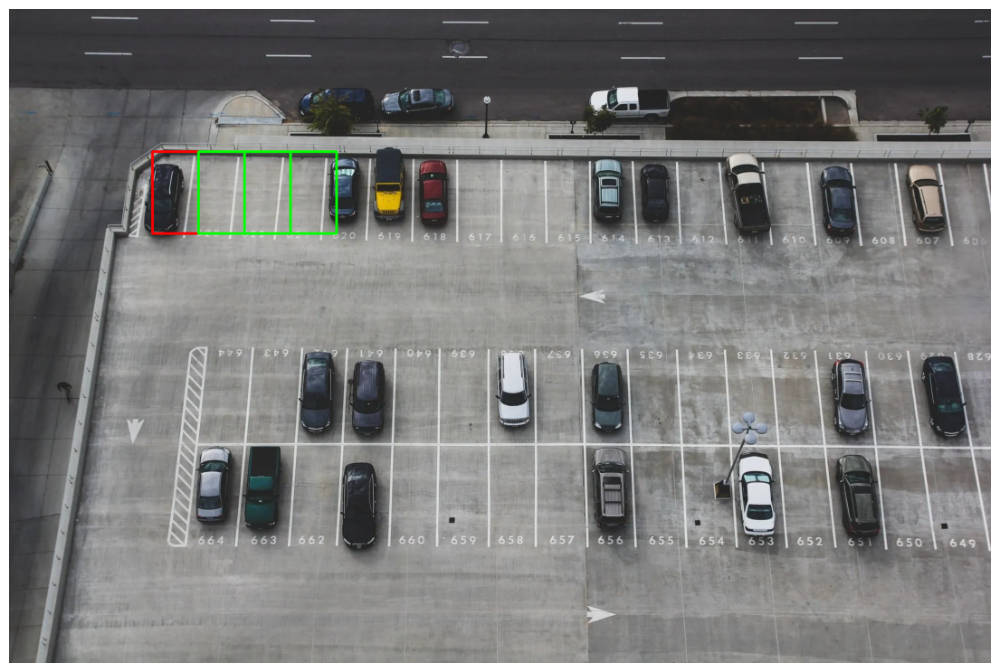

Total spaces: 4
Occupied: 1
Available: 3


In [48]:
output = image_rgb.copy()
occupied = 0
available = 0

for i, (x1, y1, x2, y2) in enumerate(parking_spaces):
    space = image_rgb[y1:y2, x1:x2]

    gray = cv2.cvtColor(space, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    density = cv2.countNonZero(edges) / edges.size

    if density > 0.08:
        color = (255, 0, 0)
        occupied += 1
    else:
        color = (0, 255, 0)
        available += 1

    cv2.rectangle(output, (x1, y1), (x2, y2), color, 3)
    print(f"Space {i+1}: Edge density = {density:.3f}")

plt.figure(figsize=(14, 10))
plt.imshow(output)
plt.axis("off")
plt.show()

print("Total spaces:", len(parking_spaces))
print("Occupied:", occupied)
print("Available:", available)

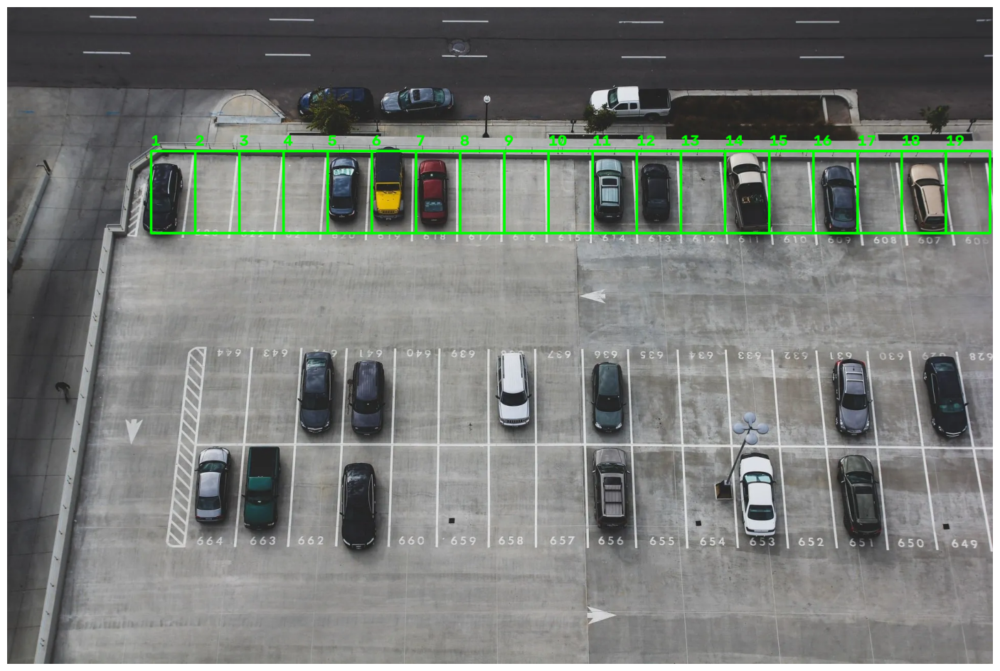

In [49]:
parking_spaces = [
    (280 + i * 86, 280, 280 + (i + 1) * 86, 440)
    for i in range(19)
]

preview = image_rgb.copy()

for i, (x1, y1, x2, y2) in enumerate(parking_spaces):
    cv2.rectangle(preview, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(preview, str(i+1), (x1, y1-10),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

plt.figure(figsize=(18, 12))
plt.imshow(preview)
plt.axis('off')
plt.show()

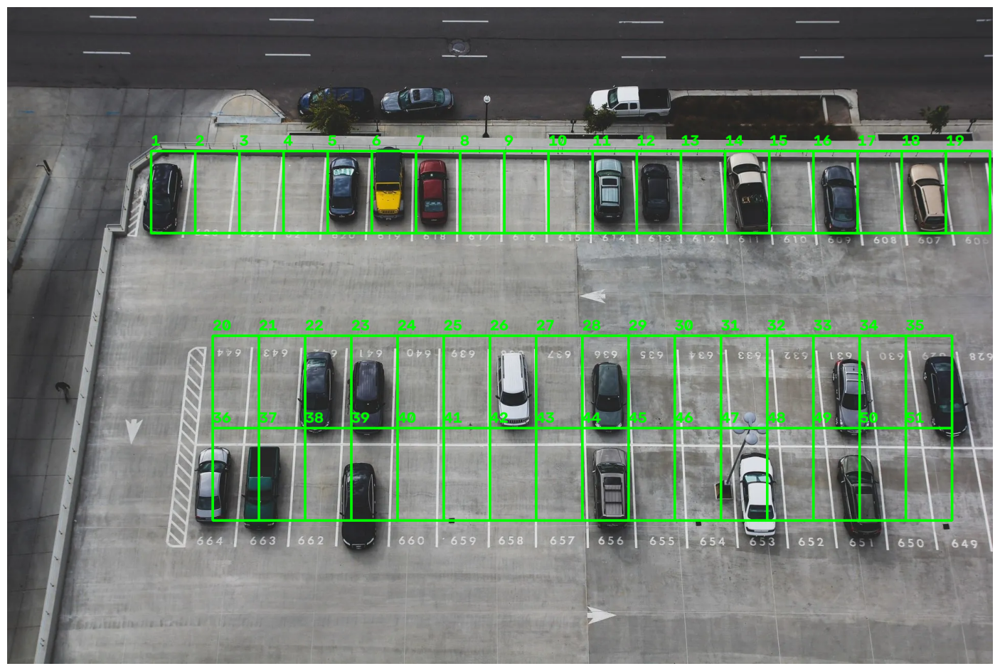

Total mapped spaces: 51


In [50]:
top_row = parking_spaces.copy()

middle_row = [
    (400 + i * 90, 640, 400 + (i + 1) * 90, 820)
    for i in range(16)
]

bottom_row = [
    (400 + i * 90, 820, 400 + (i + 1) * 90, 1000)
    for i in range(16)
]

parking_spaces = top_row + middle_row + bottom_row

preview = image_rgb.copy()

for i, (x1, y1, x2, y2) in enumerate(parking_spaces):
    cv2.rectangle(preview, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(preview, str(i+1), (x1, y1-10),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

plt.figure(figsize=(18, 12))
plt.imshow(preview)
plt.axis('off')
plt.show()

print("Total mapped spaces:", len(parking_spaces))

In [51]:
top_row = [
    (280 + i * 86, 280, 280 + (i + 1) * 86, 440)
    for i in range(19)
]

middle_row = [
    (380 + i * 95, 665, 380 + (i + 1) * 95, 845)
    for i in range(16)
]

bottom_row = [
    (365 + i * 95, 845, 365 + (i + 1) * 95, 1040)
    for i in range(16)
]

parking_spaces = top_row + middle_row + bottom_row

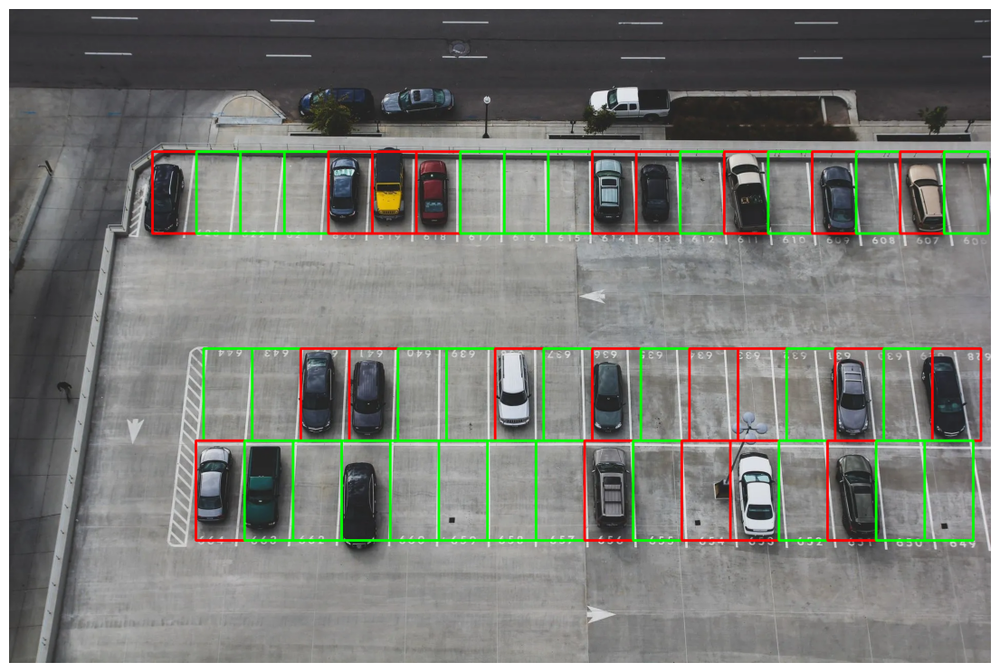

Total spaces: 51
Occupied: 22
Available: 29


In [52]:
output = image_rgb.copy()
occupied = 0
available = 0

for x1, y1, x2, y2 in parking_spaces:
    space = image_rgb[y1+10:y2-10, x1+10:x2-10]

    gray = cv2.cvtColor(space, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    density = cv2.countNonZero(edges) / edges.size

    if density > 0.08:
        color = (255, 0, 0)
        occupied += 1
    else:
        color = (0, 255, 0)
        available += 1

    cv2.rectangle(output, (x1, y1), (x2, y2), color, 3)

plt.figure(figsize=(14, 10))
plt.imshow(output)
plt.axis("off")
plt.show()

print("Total spaces:", len(parking_spaces))
print("Occupied:", occupied)
print("Available:", available)

In [53]:
actual_occupied = 21
actual_available = 30

false_positives = 3
false_negatives = 2

total_spaces = len(parking_spaces)
correct_predictions = total_spaces - false_positives - false_negatives

accuracy = (correct_predictions / total_spaces) * 100

print("Total spaces:", total_spaces)
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", false_positives + false_negatives)
print(f"Detection accuracy: {accuracy:.2f}%")

Total spaces: 51
Correct predictions: 46
Incorrect predictions: 5
Detection accuracy: 90.20%


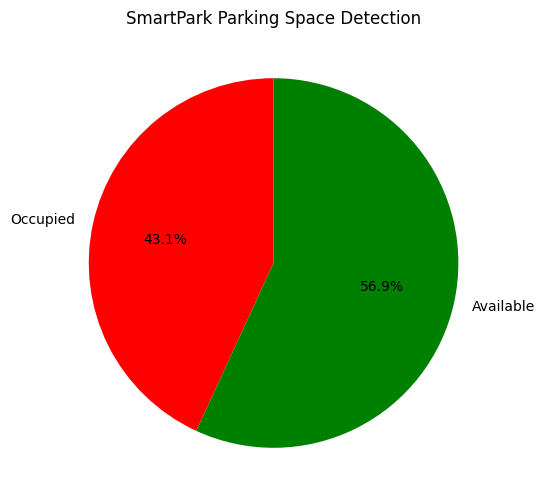

In [54]:
labels = ['Occupied', 'Available']
values = [occupied, available]
colors = ['red', 'green']

plt.figure(figsize=(6, 6))
plt.pie(values, labels=labels, colors=colors,
        autopct='%1.1f%%', startangle=90)
plt.title('SmartPark Parking Space Detection')
plt.show()

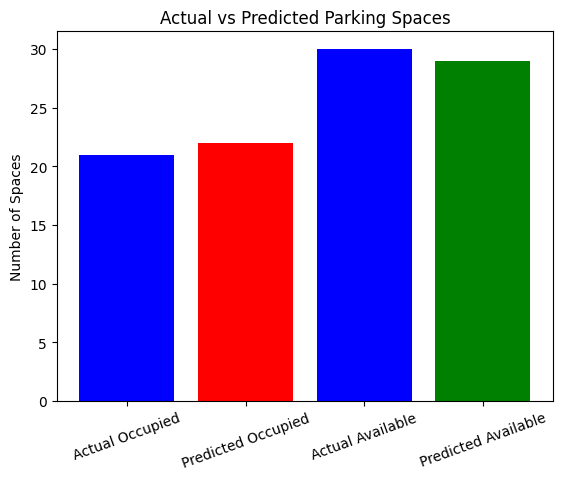

In [55]:
labels = ['Occupied', 'Available']

plt.bar(['Actual Occupied', 'Predicted Occupied',
         'Actual Available', 'Predicted Available'],
        [actual_occupied, occupied,
         actual_available, available],
        color=['blue', 'red', 'blue', 'green'])

plt.title('Actual vs Predicted Parking Spaces')
plt.ylabel('Number of Spaces')
plt.xticks(rotation=20)
plt.show()

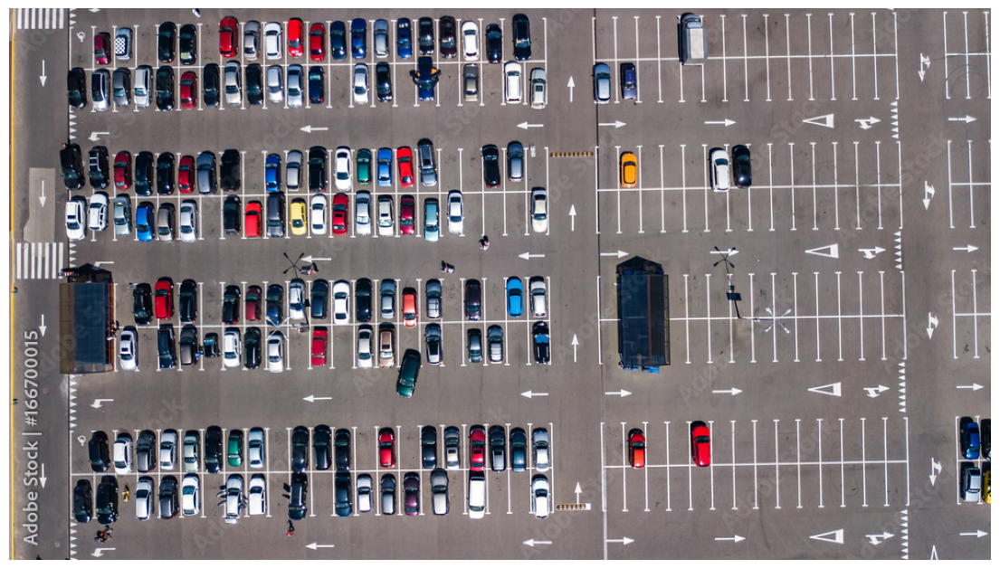

Image dimensions: (562, 1000, 3)


In [56]:
test_image = cv2.imread('/content/store parking lot.jpg')
test_rgb = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 10))
plt.imshow(test_rgb)
plt.axis('off')
plt.show()

print("Image dimensions:", test_rgb.shape)

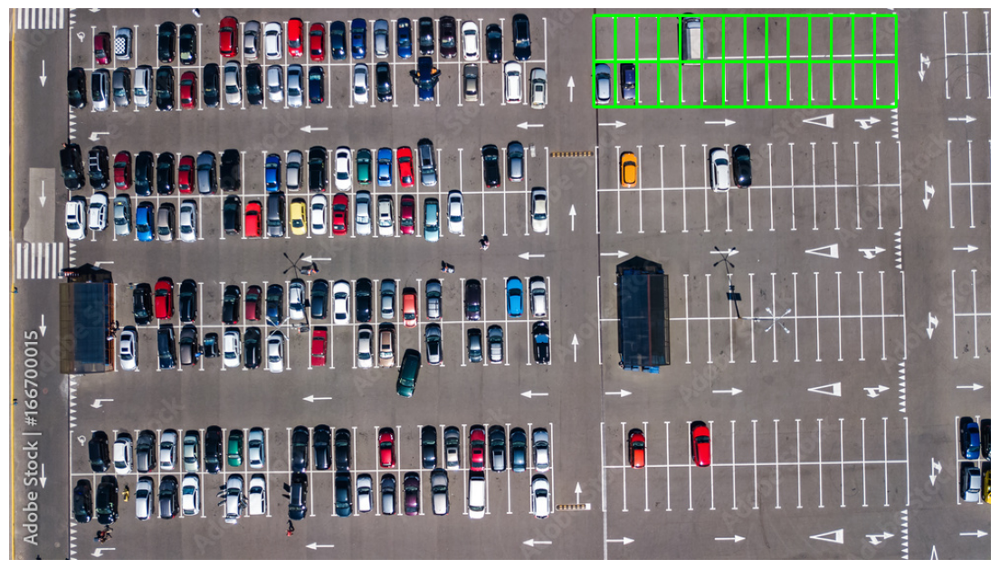

Total test spaces: 28


In [57]:
test_spaces = [
    (595 + i * 22, 7, 595 + (i + 1) * 22, 54)
    for i in range(14)
]

test_spaces += [
    (595 + i * 22, 54, 595 + (i + 1) * 22, 100)
    for i in range(14)
]

test_preview = test_rgb.copy()

for x1, y1, x2, y2 in test_spaces:
    cv2.rectangle(test_preview, (x1, y1),
                  (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(14, 10))
plt.imshow(test_preview)
plt.axis('off')
plt.show()

print("Total test spaces:", len(test_spaces))

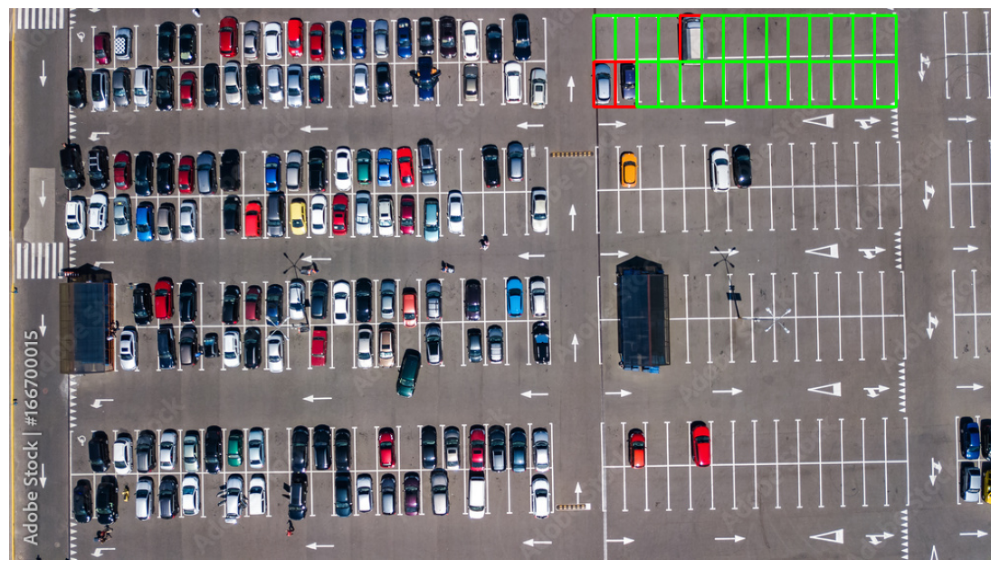

Total test spaces: 28
Occupied: 3
Available: 25


In [58]:
test_output = test_rgb.copy()
test_occupied = 0
test_available = 0

for x1, y1, x2, y2 in test_spaces:
    space = test_rgb[y1+10:y2-10, x1+10:x2-10]

    gray = cv2.cvtColor(space, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    density = cv2.countNonZero(edges) / edges.size

    if density > 0.08:
        color = (255, 0, 0)
        test_occupied += 1
    else:
        color = (0, 255, 0)
        test_available += 1

    cv2.rectangle(test_output, (x1, y1),
                  (x2, y2), color, 2)

plt.figure(figsize=(14, 10))
plt.imshow(test_output)
plt.axis('off')
plt.show()

print("Total test spaces:", len(test_spaces))
print("Occupied:", test_occupied)
print("Available:", test_available)

In [59]:
test_actual_occupied = 3
test_actual_available = 25

test_false_positives = 0
test_false_negatives = 0

test_total = len(test_spaces)

test_correct = test_total - test_false_positives - test_false_negatives

test_accuracy = (test_correct / test_total) * 100

print("Total test spaces:", test_total)
print("Correct predictions:", test_correct)
print("Incorrect predictions:", test_total - test_correct)
print(f"Test accuracy: {test_accuracy:.2f}%")

Total test spaces: 28
Correct predictions: 28
Incorrect predictions: 0
Test accuracy: 100.00%


In [60]:
combined_total = total_spaces + test_total
combined_correct = correct_predictions + test_correct
combined_incorrect = combined_total - combined_correct

combined_accuracy = (combined_correct / combined_total) * 100

print("Total parking spaces:", combined_total)
print("Correct predictions:", combined_correct)
print("Incorrect predictions:", combined_incorrect)
print(f"Combined accuracy: {combined_accuracy:.2f}%")

Total parking spaces: 79
Correct predictions: 74
Incorrect predictions: 5
Combined accuracy: 93.67%


## Conclusion

The SmartPark project uses computer vision and OpenCV to identify occupied and available parking spaces. The system uses Canny edge detection to analyze manually mapped parking spaces.

The first image contained 51 mapped parking spaces. The system correctly classified 46 spaces, achieving an accuracy of 90.20%. Five spaces were incorrectly classified, including three false positives and two false negatives.

The second image contained 28 mapped parking spaces. Based on visual verification, the system correctly identified three occupied spaces and 25 available spaces, achieving an accuracy of 100% within the selected area.

Across both images, the system correctly classified 74 out of 79 parking spaces, achieving a combined accuracy of 93.67%.

The project demonstrated how computer vision can be used for parking management. However, shadows, parking lines, lighting conditions, and rectangle alignment can affect detection accuracy.

Future improvements could include automatic parking space mapping, improved detection methods, testing additional images, and real-time video processing.

In [61]:
import os

os.makedirs("results", exist_ok=True)

cv2.imwrite(
    "results/parking_detection_image1.jpg",
    cv2.cvtColor(output, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    "results/parking_detection_image2.jpg",
    cv2.cvtColor(test_output, cv2.COLOR_RGB2BGR)
)

print("Results saved successfully!")

Results saved successfully!


In [62]:
import pandas as pd

results_table = pd.DataFrame({
    "Image": ["Image 1", "Image 2", "Combined"],
    "Total Spaces": [51, 28, 79],
    "Correct Predictions": [46, 28, 74],
    "Incorrect Predictions": [5, 0, 5],
    "Accuracy (%)": [90.20, 100.00, 93.67]
})

results_table.to_csv(
    "results/accuracy_results.csv", index=False
)

display(results_table)

print(os.listdir("results"))

,Image,Total Spaces,Correct Predictions,Incorrect Predictions,Accuracy (%)
0,Image 1,51,46,5,90.20
1,Image 2,28,28,0,100.00
2,Combined,79,74,5,93.67


['accuracy_results.csv', 'parking_detection_image2.jpg', 'parking_detection_image1.jpg']


In [63]:
import shutil
from google.colab import files

shutil.make_archive("SmartPark_Results", "zip", "results")

files.download("SmartPark_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>